# TC3-48 — Analisar relações temporais

**Objetivo:** avaliar diferenças e padrões entre os anos disponíveis na base consolidada, considerando o recorte do estudo: alunos da série 2 e o target `alfabetizado`.

## Relação com os notebooks anteriores

- **TC3-43:** forneceu o contexto da distribuição do target `alfabetizado`.
- **TC3-44 e TC3-45:** reforçaram a necessidade de considerar distribuição, valores ausentes e cobertura dos dados.
- **TC3-46:** investigou associações entre variáveis, incluindo a correlação elevada entre `proficiencia` e `alfabetizado`.
- **TC3-47:** comparou os resultados por município, UF e rede de ensino.

## Cuidados metodológicos

- O target `alfabetizado` será utilizado conforme recebido na base, sem recalcular sua classificação.
- A análise será restrita à série 2 quando a coluna de série estiver disponível.
- A média do target binário pode ser interpretada como proporção da classe 1.
- Diferenças entre anos são descritivas e não comprovam causalidade.
- É necessário verificar se os anos são comparáveis quanto à cobertura, à definição das variáveis e à composição dos registros.
- `id_aluno` não será utilizado para vinculação longitudinal individual: a estabilidade desse identificador entre anos não está validada para esta análise, e a documentação do Inep descreve a reestruturação dos microdados para reduzir riscos de identificação.
- As comparações temporais serão feitas por grupos agregados (por exemplo, município/ano, UF/ano e rede/ano), sem interpretar diferenças como acompanhamento dos mesmos estudantes.
- Se houver apenas dois anos, os resultados permitem comparar os períodos observados, mas não estabelecer uma tendência de longo prazo.


## 1. Preparação do ambiente

Utilizaremos Polars para consultar os arquivos Parquet e Polars/matplotlib/seaborn para apresentar tabelas e gráficos.


## Inicialização independente

Esta célula reproduz a configuração compartilhada do notebook principal. Ela prepara ambiente, caminhos e funções comuns sem alterar a lógica canônica desta etapa.


In [1]:
# =============================================================================
# CONFIGURAÇÕES PARA RODAR O NOTEBOOK
# Execute esta célula primeiro. Esta política não altera a metodologia do fluxo.
# =============================================================================
import os
import sys
import gc
import ctypes
import polars as pl
from datetime import datetime, timezone

# Opções do usuário
PERFIL_RECURSOS = "auto"       # auto | baixo | medio | normal | alto
LIMITE_RAM_PERCENTUAL = None    # None = automático; ou inteiro entre 50 e 90
MAX_THREADS = None              # None = automático; ou inteiro >= 1
USAR_GPU = os.getenv("TC3_USAR_GPU", "1").strip().lower() in {"1", "true", "sim", "yes"}                 # requer WSL2 + RAPIDS/cuML + kernel tc3-gpu

REUTILIZAR_ARTEFATOS = False  # False reconstrói; True aceita caches válidos
SALVAR_ARTEFATOS = True       # False usa somente área temporária da sessão


# Protocolo metodologico compartilhado por todas as fases e modelos.
SEED_GLOBAL = 42
EXECUTAR_SHAP = os.getenv("TC3_EXECUTAR_SHAP", "0").strip().lower() in {"1", "true", "sim", "yes"}
AMOSTRA_SHAP = max(20, int(os.getenv("TC3_AMOSTRA_SHAP", "100")))
AMOSTRA_BACKGROUND_SHAP = max(20, int(os.getenv("TC3_BACKGROUND_SHAP", "50")))
CHAVE_GRUPO_GLOBAL = "chave_escola_ano"
N_SPLITS_CV_GLOBAL = 3
N_ITER_BUSCA_GLOBAL = 10
LIMIAR_CLASSIFICACAO_GLOBAL = 0.50
REPETICOES_PERMUTACAO_GLOBAL = 5
REPETICOES_BOOTSTRAP_GLOBAL = 200

N_JOBS_MODELAGEM_GLOBAL = 1
N_SPLITS_HOLDOUT_GLOBAL = 1
SCORING_PRINCIPAL_GLOBAL = "roc_auc"
VERBOSE_BUSCA_GLOBAL = 2
ERRO_BUSCA_GLOBAL = "raise"
RETORNAR_SCORE_TREINO_GLOBAL = True

# Contrato comum de pre-processamento dos modelos.
IMPUTACAO_NUMERICA_GLOBAL = "median"
IMPUTACAO_CATEGORICA_GLOBAL = "most_frequent"
ONE_HOT_DESCONHECIDO_GLOBAL = "ignore"
ONE_HOT_SPARSO_GLOBAL = False  # matriz densa: evita fallback dos modelos para CPU
SPARSE_THRESHOLD_GLOBAL = 0.0
ESCALONADOR_CENTRALIZAR_GLOBAL = False


# Percentuais de amostragem (0 < valor <= 1). Alterar aqui afeta todo o notebook.
# O teste final permanece integral (100%); as amostras menores servem apenas ao
# desenvolvimento, comparacao de modelos e interpretabilidade.
FRACOES_AMOSTRAGEM = {
    "eda_correlacao": 0.05,
    "validacao_preparacao": 0.02,
    "fase5_modelos": 0.10,
    "fase5_knn": 0.02,  # KNN tem custo de memoria e predicao maior.
    "fase6_desenvolvimento": 0.12,
    "fase6_validacao_interna": 0.25,
    "fase7_desenvolvimento": 1.00,
    "fase7_teste": 1.00,
    "interpretacao": 0.035,
    "bootstrap": 0.17,
}

for _nome, _fracao in FRACOES_AMOSTRAGEM.items():
    if not 0 < _fracao <= 1:
        raise ValueError(f"Fracao invalida em FRACOES_AMOSTRAGEM[{_nome!r}]: {_fracao}")


def tamanho_por_fracao(total, fracao):
    """Converte uma proporcao em quantidade reproduzivel, sem exceder o total."""
    if total < 1:
        raise ValueError("Nao e possivel amostrar uma particao vazia.")
    return min(total, max(1, round(total * fracao)))


def materializar_split_percentual(dados, contrato, nome_split, fracao, seed, materializador):
    """Materializa uma fracao de um split e informa claramente o universo usado."""
    import polars as pl

    coluna_split = contrato["controle_split"]
    total = (
        dados.filter(pl.col(coluna_split) == nome_split)
        .select(pl.len().alias("total"))
        .collect()
        .item()
    )
    quantidade = tamanho_por_fracao(total, fracao)
    X, y = materializador(dados, contrato, nome_split, limit=quantidade, seed=seed)
    print(f"{nome_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return X, y


def _estado_memoria_sistema():
    """Retorna RAM total e disponível em bytes."""
    valores = {}
    try:
        with open("/proc/meminfo", encoding="utf-8") as arquivo:
            for linha in arquivo:
                chave, valor = linha.split(":", 1)
                valores[chave] = int(valor.strip().split()[0]) * 1024
        return valores["MemTotal"], valores.get("MemAvailable", valores.get("MemFree", 0))
    except (OSError, KeyError, ValueError):
        try:
            return (
                os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
                os.sysconf("SC_AVPHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
            )
        except (AttributeError, OSError, ValueError):
            return None, None


RAM_TOTAL_BYTES, RAM_DISPONIVEL_BYTES = _estado_memoria_sistema()
RAM_TOTAL_GB = RAM_TOTAL_BYTES / 1024**3 if RAM_TOTAL_BYTES else 0.0
CPUS_LOGICAS = os.cpu_count() or 1

if RAM_TOTAL_GB and RAM_TOTAL_GB <= 4.5:
    _perfil_detectado = "baixo"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 8.5:
    _perfil_detectado = "medio"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 16.5:
    _perfil_detectado = "normal"
else:
    _perfil_detectado = "alto"

_perfis = {
    "baixo": (60, 1),
    "medio": (70, min(2, CPUS_LOGICAS)),
    "normal": (75, min(4, CPUS_LOGICAS)),
    "alto": (80, min(8, max(1, CPUS_LOGICAS // 2))),
}
PERFIL_ATIVO = _perfil_detectado if PERFIL_RECURSOS == "auto" else PERFIL_RECURSOS.lower()
if PERFIL_ATIVO not in _perfis:
    raise ValueError("PERFIL_RECURSOS deve ser auto, baixo, medio, normal ou alto.")

_limite_perfil, _threads_perfil = _perfis[PERFIL_ATIVO]
LIMITE_RAM_ATIVO = _limite_perfil if LIMITE_RAM_PERCENTUAL is None else int(LIMITE_RAM_PERCENTUAL)
THREADS_MAXIMAS = _threads_perfil if MAX_THREADS is None else int(MAX_THREADS)
if not 50 <= LIMITE_RAM_ATIVO <= 90:
    raise ValueError("LIMITE_RAM_PERCENTUAL deve ficar entre 50 e 90.")
if THREADS_MAXIMAS < 1:
    raise ValueError("MAX_THREADS deve ser pelo menos 1.")
THREADS_MAXIMAS = min(THREADS_MAXIMAS, CPUS_LOGICAS)

# Definido antes de NumPy, Polars, scikit-learn e cuML serem importados.
for _variavel, _valor in {
    "OMP_NUM_THREADS": str(THREADS_MAXIMAS),
    "OPENBLAS_NUM_THREADS": str(THREADS_MAXIMAS),
    "MKL_NUM_THREADS": str(THREADS_MAXIMAS),
    "NUMEXPR_NUM_THREADS": str(THREADS_MAXIMAS),
    "VECLIB_MAXIMUM_THREADS": str(THREADS_MAXIMAS),
    "POLARS_MAX_THREADS": str(THREADS_MAXIMAS),
    "MALLOC_ARENA_MAX": "2",
}.items():
    os.environ[_variavel] = _valor

HISTORICO_RECURSOS = []
_estado_recursos = {"nivel": None, "threads": None, "contexto_threads": None}


def _aplicar_threads(limite):
    """Limita pools BLAS/OpenMP já carregados; Polars usa o limite inicial."""
    limite = max(1, min(int(limite), THREADS_MAXIMAS))
    if _estado_recursos["threads"] == limite:
        return
    anterior = _estado_recursos.get("contexto_threads")
    if anterior is not None:
        try:
            anterior.__exit__(None, None, None)
        except Exception:
            pass
    try:
        from threadpoolctl import threadpool_limits
        contexto = threadpool_limits(limits=limite)
        contexto.__enter__()
    except Exception:
        contexto = None
    _estado_recursos["contexto_threads"] = contexto
    _estado_recursos["threads"] = limite


def _liberar_memoria_global(agressiva=False):
    """Libera caches transitórios sem apagar variáveis usadas pelo fluxo."""
    shell = get_ipython()
    if shell is not None:
        for nome in ("_", "__", "___"):
            shell.user_ns[nome] = None
    gc.collect()
    modulo_cupy = sys.modules.get("cupy")
    if modulo_cupy is not None:
        try:
            modulo_cupy.get_default_memory_pool().free_all_blocks()
            modulo_cupy.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass
    if agressiva:
        modulo_plt = sys.modules.get("matplotlib.pyplot")
        if modulo_plt is not None:
            try:
                modulo_plt.close("all")
            except Exception:
                pass
        try:
            ctypes.CDLL("libc.so.6").malloc_trim(0)
        except (OSError, AttributeError):
            pass


def _gerenciar_recursos(*_args, **_kwargs):
    """Reduz paralelismo progressivamente e nunca interrompe uma célula."""
    total, disponivel = _estado_memoria_sistema()
    if not total:
        return
    uso = 100.0 * (total - disponivel) / total
    margem = LIMITE_RAM_ATIVO - uso
    if margem > 15:
        nivel, threads, limpar = "normal", THREADS_MAXIMAS, False
    elif margem > 7:
        nivel, threads, limpar = "moderado", max(1, THREADS_MAXIMAS // 2), True
    else:
        nivel, threads, limpar = "conservador", 1, True

    _aplicar_threads(threads)
    if limpar:
        _liberar_memoria_global(agressiva=margem <= 0)

    if nivel != _estado_recursos["nivel"]:
        registro = {
            "instante_utc": datetime.now(timezone.utc).isoformat(),
            "nivel": nivel,
            "threads": threads,
            "ram_usada_percentual": round(uso, 1),
            "ram_disponivel_gb": round(disponivel / 1024**3, 2),
        }
        HISTORICO_RECURSOS.append(registro)
        print(
            f"[recursos] nível={nivel}; threads={threads}; "
            f"RAM usada={uso:.1f}%; livre={disponivel / 1024**3:.1f} GB."
        )
        _estado_recursos["nivel"] = nivel


ipython = get_ipython()
if ipython is not None:
    # Impede callbacks duplicados ao reexecutar a configuração.
    for _atributo in ("_tc3_memory_guard", "_tc3_resource_guard"):
        _guard_anterior = getattr(ipython, _atributo, None)
        if _guard_anterior is not None:
            for _evento, _funcao in _guard_anterior:
                try:
                    ipython.events.unregister(_evento, _funcao)
                except (ValueError, KeyError):
                    pass
    _callbacks_recursos = [
        ("pre_run_cell", _gerenciar_recursos),
        ("post_run_cell", _gerenciar_recursos),
    ]
    for _evento, _funcao in _callbacks_recursos:
        ipython.events.register(_evento, _funcao)
    ipython._tc3_resource_guard = _callbacks_recursos

_gerenciar_recursos()
print(
    "Configuração automática ativa: "
    f"perfil={PERFIL_ATIVO}; RAM={RAM_TOTAL_GB:.1f} GB; CPUs={CPUS_LOGICAS}; "
    f"limite preventivo={LIMITE_RAM_ATIVO}%; threads máximas={THREADS_MAXIMAS}."
)

# Backend GPU: ativado antes de qualquer importação do scikit-learn.
cuda_conda = os.path.join(sys.prefix, "targets", "x86_64-linux")
if os.path.exists(os.path.join(cuda_conda, "include", "cuda.h")):
    os.environ.setdefault("CUDA_PATH", cuda_conda)
if USAR_GPU:
    try:
        from cuml.accel import install
        install(log_level="info")
        import cupy as cp
        dispositivo = cp.cuda.runtime.getDeviceProperties(0)
        nome_gpu = dispositivo["name"].decode() if isinstance(dispositivo["name"], bytes) else str(dispositivo["name"])
        memoria_gpu_gb = cp.cuda.runtime.memGetInfo()[1] / 1024**3
        BACKEND_ML = f"RAPIDS cuML — {nome_gpu} ({memoria_gpu_gb:.1f} GB de VRAM)"
    except Exception as exc:
        raise RuntimeError("GPU/RAPIDS indisponível. Abra no WSL2 e selecione o kernel tc3-gpu.") from exc
else:
    BACKEND_ML = "scikit-learn CPU"
print("Backend de Machine Learning:", BACKEND_ML)

from pathlib import Path
import hashlib
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

def localizar_raiz(inicio: Path) -> Path:
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "dados").is_dir() and (candidato / "notebooks").is_dir():
            return candidato
    raise FileNotFoundError("Execute este notebook dentro do repositório tech_challenge_3.")

PROJECT_ROOT = localizar_raiz(Path.cwd().resolve())
print("Raiz do projeto:", PROJECT_ROOT)


# Contrato único de diretórios. Fontes sempre são lidas da área imutável.
import tempfile

FONTES_ORIGINAIS_DIR = PROJECT_ROOT / "dados" / "fontes_originais"
_TEMP_BASE = PROJECT_ROOT / ".execucao_temporaria"
_TEMP_BASE.mkdir(parents=True, exist_ok=True)
if SALVAR_ARTEFATOS:
    RAIZ_ARTEFATOS = PROJECT_ROOT
    _DIRETORIO_TEMPORARIO = None
else:
    _DIRETORIO_TEMPORARIO = tempfile.TemporaryDirectory(prefix="tc3_", dir=_TEMP_BASE)
    RAIZ_ARTEFATOS = Path(_DIRETORIO_TEMPORARIO.name)

DADOS_PROCESSADOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_processados"
DADOS_ANALITICOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_analiticos"
RESULTADOS_DIR = RAIZ_ARTEFATOS / "resultados"
RESULTADOS_FIGURAS_DIR = RESULTADOS_DIR / "figuras"
RESULTADOS_TABELAS_DIR = RESULTADOS_DIR / "tabelas"
RESULTADOS_METRICAS_DIR = RESULTADOS_DIR / "metricas"
RESULTADOS_RELATORIOS_DIR = RESULTADOS_DIR / "relatorios"
MODELOS_DIR = RAIZ_ARTEFATOS / "modelos"

for _diretorio_saida in (
    DADOS_PROCESSADOS_DIR, DADOS_ANALITICOS_DIR, RESULTADOS_FIGURAS_DIR,
    RESULTADOS_TABELAS_DIR, RESULTADOS_METRICAS_DIR,
    RESULTADOS_RELATORIOS_DIR, MODELOS_DIR,
):
    _diretorio_saida.mkdir(parents=True, exist_ok=True)

def deve_recalcular(caminho):
    """True quando o cache deve ser ignorado ou ainda não existe."""
    return not REUTILIZAR_ARTEFATOS or not Path(caminho).exists()


def publicar_parquet_particionado(frame, destino, *, particionar_por):
    """Publica partições sequencialmente e troca o diretório de forma atômica.

    O ``write_parquet(partition_by=...)`` do Polars prepara várias partições em
    paralelo e pode duplicar o pico de RAM de bases já materializadas. Esta
    implementação mantém apenas uma partição adicional em memória por vez.
    """
    import gc
    import shutil

    destino = Path(destino)
    temporario = destino.with_name(destino.name + "__publicacao_tmp")
    anterior = destino.with_name(destino.name + "__publicacao_anterior")
    for caminho in (temporario, anterior):
        if caminho.exists():
            shutil.rmtree(caminho)
    temporario.mkdir(parents=True, exist_ok=True)

    lazy = frame if isinstance(frame, pl.LazyFrame) else frame.lazy()
    schema = lazy.collect_schema()
    if particionar_por not in schema.names():
        raise ValueError(f"Coluna de particionamento ausente: {particionar_por}")

    valores = (
        lazy.select(pl.col(particionar_por).unique())
        .collect(engine="streaming")
        .get_column(particionar_por)
        .to_list()
    )
    valores = sorted(valores, key=lambda valor: (valor is None, str(valor)))
    if not valores:
        raise RuntimeError("Não há valores para particionar a publicação.")

    arquivos_novos = []
    for indice, valor in enumerate(valores):
        valor_hive = "__HIVE_DEFAULT_PARTITION__" if valor is None else str(valor)
        if any(separador in valor_hive for separador in ("/", "\\")):
            raise ValueError(f"Valor de partição inválido: {valor_hive!r}")
        diretorio_particao = temporario / f"{particionar_por}={valor_hive}"
        diretorio_particao.mkdir(parents=True, exist_ok=True)
        arquivo = diretorio_particao / f"part-{indice:05d}.parquet"
        predicado = pl.col(particionar_por).is_null() if valor is None else pl.col(particionar_por) == pl.lit(valor)
        lazy.filter(predicado).sink_parquet(
            arquivo,
            compression="zstd",
            statistics=True,
            row_group_size=100_000,
            mkdir=True,
            engine="streaming",
        )
        if not arquivo.is_file() or arquivo.stat().st_size == 0:
            raise RuntimeError(f"Partição não foi gravada corretamente: {arquivo}")
        arquivos_novos.append(arquivo)
        gc.collect()

    if destino.exists():
        destino.replace(anterior)
    try:
        try:
            temporario.replace(destino)
        except OSError:
            # Volumes Docker montados do Windows podem bloquear rename de diretórios.
            # O fallback copia a publicação pronta e remove a área temporária.
            shutil.copytree(temporario, destino)
            shutil.rmtree(temporario)
    except Exception:
        if destino.exists():
            shutil.rmtree(destino)
        if anterior.exists():
            anterior.replace(destino)
        raise
    if anterior.exists():
        shutil.rmtree(anterior)
    return len(arquivos_novos)


def salvar_figura_eda(figura, nome):
    """Exporta uma figura exploratória sem alterar sua exibição no notebook."""
    destino = RESULTADOS_FIGURAS_DIR / "fluxo_exploratorio" / nome
    destino.parent.mkdir(parents=True, exist_ok=True)
    figura.savefig(destino, dpi=180, bbox_inches="tight")
    return destino

print("Fontes originais:", FONTES_ORIGINAIS_DIR)
print("Destino dos artefatos:", RAIZ_ARTEFATOS)
print("Reutilizar artefatos:", REUTILIZAR_ARTEFATOS, "| Salvar:", SALVAR_ARTEFATOS)

# Imports compartilhados que, no fluxo completo, são carregados por etapas anteriores.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


[recursos] nível=normal; threads=4; RAM usada=29.2%; livre=11.0 GB.
Configuração automática ativa: perfil=normal; RAM=15.5 GB; CPUs=20; limite preventivo=75%; threads máximas=4.
[cuml.accel] Accelerator installed.
Backend de Machine Learning: RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)
Raiz do projeto: /workspace
Fontes originais: /workspace/dados/fontes_originais
Destino dos artefatos: /workspace
Reutilizar artefatos: False | Salvar: True


In [2]:
from pathlib import Path
import warnings

import polars as pl
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

print("Polars:", pl.__version__)


Polars: 2.0.0


## 2. Localização e leitura dos arquivos

O código procura a pasta da base a partir do diretório atual e de seus diretórios pais. Se a estrutura local for diferente, ajuste `BASE_PATH` para apontar para a pasta `base_alunos_municipios_por_uf`.


In [3]:
NOME_PASTA_BASE = "base_alunos_municipios_por_uf"
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / NOME_PASTA_BASE
if not BASE_PATH.exists():
    raise FileNotFoundError(
        f"Base consolidada ausente em {BASE_PATH}. Execute as etapas anteriores do notebook."
    )

arquivos_parquet = sorted(BASE_PATH.glob("sigla_uf=*/*.parquet"))

if not arquivos_parquet:
    raise FileNotFoundError(f"Nenhum arquivo Parquet encontrado em {BASE_PATH}")

lf = pl.scan_parquet([str(p) for p in arquivos_parquet], hive_partitioning=True)
schema = lf.collect_schema()
colunas = schema.names()

print("Pasta da base:", BASE_PATH)
print("Quantidade de arquivos Parquet:", len(arquivos_parquet))
print("Quantidade de colunas:", len(colunas))
print("Quantidade de registros:", lf.select(pl.len()).collect().item())


Pasta da base: /workspace/dados/dados_processados/consolidado/base_alunos_municipios_por_uf
Quantidade de arquivos Parquet: 26
Quantidade de colunas: 49
Quantidade de registros: 3867999


## 3. Identificação das dimensões e indicadores

Esta etapa verifica quais colunas temporais e educacionais estão disponíveis, evitando assumir que todos os nomes existem em todas as versões da base.


In [4]:
def primeira_coluna(candidatas, disponiveis):
    return next((c for c in candidatas if c in disponiveis), None)

COL_ANO = primeira_coluna(
    ["ano_referencia", "ano", "ano_base", "ano_letivo", "nu_ano"],
    colunas
)
COL_SERIE = primeira_coluna(
    ["serie", "ano_escolar", "etapa", "etapa_ensino"],
    colunas
)
COL_TARGET = "alfabetizado" if "alfabetizado" in colunas else None
COL_PROFICIENCIA = "proficiencia" if "proficiencia" in colunas else None
COL_PRESENCA = "presenca" if "presenca" in colunas else None
COL_PREENCHIMENTO = "preenchimento_caderno" if "preenchimento_caderno" in colunas else None
COL_UF = primeira_coluna(["sigla_uf", "uf", "nome_uf"], colunas)
COL_MUNICIPIO = primeira_coluna(["id_municipio", "codigo_municipio", "cod_municipio"], colunas)
COL_REDE = primeira_coluna(["rede_descricao", "rede", "tipo_rede"], colunas)

display(pl.DataFrame([
    {"dimensao_ou_indicador": nome, "coluna_detectada": coluna, "disponivel": coluna is not None}
    for nome, coluna in [
        ("Ano de referência", COL_ANO),
        ("Série", COL_SERIE),
        ("Target alfabetizado", COL_TARGET),
        ("Proficiência", COL_PROFICIENCIA),
        ("Presença", COL_PRESENCA),
        ("Preenchimento do caderno", COL_PREENCHIMENTO),
        ("UF", COL_UF),
        ("Município", COL_MUNICIPIO),
        ("Rede de ensino", COL_REDE),
    ]
]))

if COL_ANO is None:
    raise ValueError(
        "Não foi encontrada uma coluna de ano reconhecida. Confira as colunas acima "
        "e ajuste a lista de candidatas em COL_ANO."
    )

if COL_TARGET is None:
    raise ValueError("A coluna 'alfabetizado' não foi encontrada na base.")


dimensao_ou_indicador,coluna_detectada,disponivel
str,str,bool
"""Ano de referência""","""ano_referencia""",true
"""Série""","""serie""",true
"""Target alfabetizado""","""alfabetizado""",true
"""Proficiência""","""proficiencia""",true
"""Presença""","""presenca""",true
"""Preenchimento do caderno""","""preenchimento_caderno""",true
"""UF""","""sigla_uf""",true
"""Município""","""id_municipio""",true
"""Rede de ensino""","""rede_descricao""",true


## 4. Validar o recorte da série e a cobertura temporal

Quando a coluna de série existir, a análise será restrita à série 2. Em seguida, serão identificados os anos disponíveis e a quantidade de registros em cada ano.


In [5]:
lf_analise = lf

if COL_SERIE is not None:
    series_disponiveis = (
        lf.select(COL_SERIE)
          .drop_nulls()
          .unique()
          .sort(COL_SERIE)
          .collect()
    )
    print("Valores encontrados na coluna de série:")
    display(series_disponiveis)

    valores_serie = series_disponiveis[COL_SERIE].to_list()
    if 2 in valores_serie:
        lf_analise = lf_analise.filter(pl.col(COL_SERIE) == 2)
        print("Análise restrita à série 2.")
    else:
        warnings.warn("O valor 2 não foi encontrado na coluna de série; confira o recorte antes de interpretar os resultados.")
else:
    print("Coluna de série não encontrada; o recorte não pôde ser validado automaticamente.")

cobertura_anos = (
    lf_analise.group_by(COL_ANO)
    .agg(pl.len().alias("quantidade_registros"))
    .sort(COL_ANO)
    .collect()
)

display(cobertura_anos)
print("Quantidade de anos distintos:", cobertura_anos.height)

# Cobertura territorial por ano: comparação agregada, sem vincular estudantes individualmente.
campos_cobertura = [COL_ANO]
if COL_UF is not None:
    campos_cobertura.append(COL_UF)
if COL_MUNICIPIO is not None:
    campos_cobertura.append(COL_MUNICIPIO)

if len(campos_cobertura) > 1:
    agregacoes_cobertura = [pl.len().alias("quantidade_registros")]
    if COL_UF is not None:
        agregacoes_cobertura.append(pl.col(COL_UF).n_unique().alias("ufs_distintas"))
    if COL_MUNICIPIO is not None:
        agregacoes_cobertura.append(pl.col(COL_MUNICIPIO).n_unique().alias("municipios_distintos"))
    cobertura_territorial = (
        lf_analise.group_by(COL_ANO)
        .agg(agregacoes_cobertura)
        .sort(COL_ANO)
        .collect()
        
    )
    print("Cobertura territorial por ano:")
    display(cobertura_territorial)
else:
    print("Não há campos territoriais suficientes para resumir a cobertura por ano.")


Valores encontrados na coluna de série:


serie
i32
2


Análise restrita à série 2.


ano_referencia,quantidade_registros
i64,u32
2023,1747439
2024,2120560


Quantidade de anos distintos: 2
Cobertura territorial por ano:


ano_referencia,quantidade_registros,ufs_distintas,municipios_distintos
i64,u32,u32,u32
2023,1747439,23,4873
2024,2120560,26,5519


### Nota metodológica — identificador individual

Durante a investigação exploratória, observou-se que alguns valores de `id_aluno` aparecem associados a municípios diferentes em 2023 e 2024. Isso não será interpretado como mudança de município pelos estudantes. A documentação do Inep informa que os formatos dos microdados estão sendo reestruturados para suprimir a possibilidade de identificação de pessoas, em atendimento à LGPD; contudo, esse princípio geral não comprova, isoladamente, como o identificador específico foi gerado. Portanto, até validar sua estabilidade, `id_aluno` não será utilizado para cruzamentos longitudinais individuais. As análises deste notebook permanecem agregadas por ano e por dimensões compatíveis, como município, UF e rede.


## 5. Resumo anual dos indicadores

A tabela apresenta a quantidade de registros, a proporção da classe 1 do target e, quando disponíveis, as médias dos indicadores educacionais por ano.


In [6]:
agregacoes = [
    pl.len().alias("quantidade_registros"),
    pl.col(COL_TARGET).mean().alias("proporcao_alfabetizado"),
    pl.col(COL_TARGET).count().alias("target_validos"),
    pl.col(COL_TARGET).is_null().sum().alias("target_nulo"),
]

if COL_PROFICIENCIA is not None:
    agregacoes.extend([
        pl.col(COL_PROFICIENCIA).count().alias("proficiencia_validos"),
        pl.col(COL_PROFICIENCIA).mean().alias("proficiencia_media"),
        pl.col(COL_PROFICIENCIA).median().alias("proficiencia_mediana"),
        pl.col(COL_PROFICIENCIA).is_null().sum().alias("proficiencia_nula"),
    ])

if COL_PRESENCA is not None:
    agregacoes.extend([
        pl.col(COL_PRESENCA).count().alias("presenca_validos"),
        pl.col(COL_PRESENCA).mean().alias("presenca_media"),
    ])

if COL_PREENCHIMENTO is not None:
    agregacoes.extend([
        pl.col(COL_PREENCHIMENTO).count().alias("preenchimento_validos"),
        pl.col(COL_PREENCHIMENTO).mean().alias("preenchimento_caderno_medio"),
    ])

resumo_anual = (
    lf_analise.group_by(COL_ANO)
    .agg(agregacoes)
    .sort(COL_ANO)
    .collect()
    
)

display(resumo_anual)


ano_referencia,quantidade_registros,proporcao_alfabetizado,target_validos,target_nulo,proficiencia_validos,proficiencia_media,proficiencia_mediana,proficiencia_nula,presenca_validos,presenca_media,preenchimento_validos,preenchimento_caderno_medio
i64,u32,f64,u32,u32,u32,f64,f64,u32,u32,f64,u32,f64
2023,1747439,0.502122,1747439,0,1502809,747.563828,752.147831,244630,1747439,0.860149,1747439,0.860007
2024,2120560,0.522088,2120560,0,1851852,749.042072,753.95,268708,2120560,0.873726,2120560,0.873284


## 6. Evolução da proporção de registros na classe 1

O gráfico mostra a proporção anual de registros com `alfabetizado = 1`. Ele descreve os anos observados e não representa, por si só, o índice oficial de alfabetização.


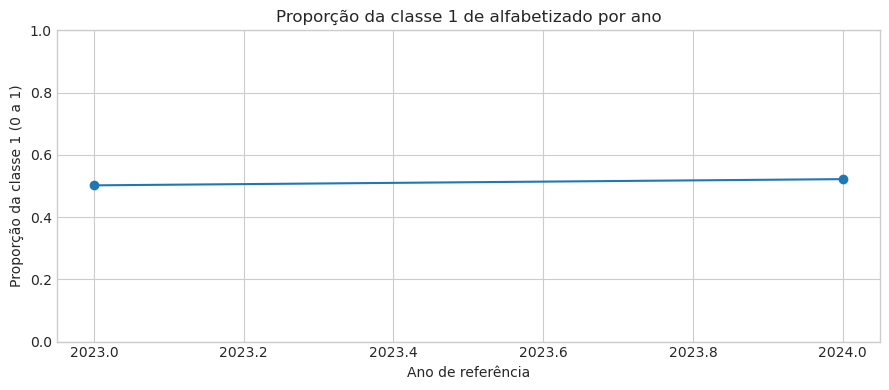

In [7]:
grafico_target=resumo_anual.drop_nulls("proporcao_alfabetizado")
if not grafico_target.is_empty():
    plt.figure(figsize=(9,4)); plt.plot(grafico_target[COL_ANO].to_numpy(),grafico_target["proporcao_alfabetizado"].to_numpy(),marker="o"); plt.title("Proporção da classe 1 de alfabetizado por ano"); plt.xlabel("Ano de referência"); plt.ylabel("Proporção da classe 1 (0 a 1)"); plt.ylim(0,1); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"257_6_evolucao_da_proporcao_de_registros_na_classe_1_01.png"); plt.show()
else: print("Não há valores válidos de alfabetizado para gerar o gráfico.")


## 7. Evolução da proficiência

Quando a variável estiver disponível, comparamos a média e a mediana da proficiência por ano. A comparação deve considerar eventuais mudanças de cobertura e de composição dos registros.


ano_referencia,indicador,valor
i64,str,f64
2023,"""proficiencia_media""",747.563828
2024,"""proficiencia_media""",749.042072
2023,"""proficiencia_mediana""",752.147831
2024,"""proficiencia_mediana""",753.95


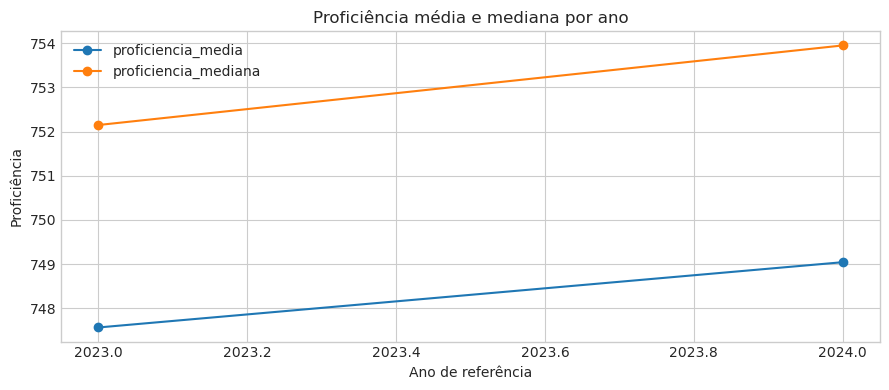

In [8]:
if COL_PROFICIENCIA is not None and "proficiencia_media" in resumo_anual.columns:
    proficiencia_long = resumo_anual.unpivot(
        index=[COL_ANO],
        on=[c for c in ["proficiencia_media", "proficiencia_mediana"] if c in resumo_anual.columns],
        variable_name="indicador",
        value_name="valor"
    )

    display(proficiencia_long)

    plt.figure(figsize=(9, 4))
    for indicador in proficiencia_long["indicador"].unique().to_list():
        trecho = proficiencia_long.filter(pl.col("indicador") == indicador).sort(COL_ANO)
        plt.plot(trecho[COL_ANO].to_numpy(), trecho["valor"].to_numpy(), marker="o", label=indicador)
    plt.legend()
    plt.title("Proficiência média e mediana por ano")
    plt.xlabel("Ano de referência")
    plt.ylabel("Proficiência")
    plt.tight_layout()
    salvar_figura_eda(plt.gcf(), "259_7_evolucao_da_proficiencia_01.png"); plt.show()
else:
    print("A variável proficiencia não está disponível; gráfico não gerado.")


## 8. Variação entre anos consecutivos

A tabela calcula diferenças entre as linhas anuais ordenadas. Antes de interpretar como variação entre anos consecutivos, confirme que os anos são de fato consecutivos e que cobertura e definições são comparáveis. A variação da proporção é apresentada em pontos percentuais. Não é uma análise longitudinal dos mesmos alunos.


In [9]:
resumo_ordenado=resumo_anual.with_columns(pl.col(COL_ANO).cast(pl.Float64,strict=False).alias("_ano_ordem")).sort("_ano_ordem")
indicadores_variacao=[c for c in ["quantidade_registros","proporcao_alfabetizado","proficiencia_media","proficiencia_mediana","presenca_media","preenchimento_caderno_medio"] if c in resumo_ordenado.columns]
variacoes=resumo_ordenado.select([COL_ANO,*indicadores_variacao]).with_columns([pl.col(c).diff().alias(f"variacao_{c}") for c in indicadores_variacao])
if "variacao_proporcao_alfabetizado" in variacoes.columns: variacoes=variacoes.with_columns((100*pl.col("variacao_proporcao_alfabetizado")).alias("variacao_proporcao_pontos_percentuais"))
display(variacoes)


ano_referencia,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio,variacao_quantidade_registros,variacao_proporcao_alfabetizado,variacao_proficiencia_media,variacao_proficiencia_mediana,variacao_presenca_media,variacao_preenchimento_caderno_medio,variacao_proporcao_pontos_percentuais
i64,u32,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64
2023,1747439,0.502122,747.563828,752.147831,0.860149,0.860007,null,null,null,null,null,null,null
2024,2120560,0.522088,749.042072,753.95,0.873726,0.873284,373121,0.019966,1.478244,1.802169,0.013577,0.013278,1.996636


## 9. Comparação temporal por UF

Quando a coluna de UF estiver disponível, esta análise compara a proporção da classe 1 por UF e ano. O gráfico usa apenas os grupos observados; mudanças na quantidade de registros devem ser consideradas na interpretação.


ano_referencia,sigla_uf,quantidade_registros,proporcao_alfabetizado
i64,str,u32,f64
2023,"""AL""",35503,0.410782
2023,"""AM""",63055,0.405709
2023,"""AP""",12349,0.373229
2023,"""BA""",137724,0.315747
2023,"""CE""",100349,0.806605
…,…,…,…
2024,"""AM""",58608,0.396499
2024,"""AP""",12580,0.421463
2024,"""BA""",115576,0.323804


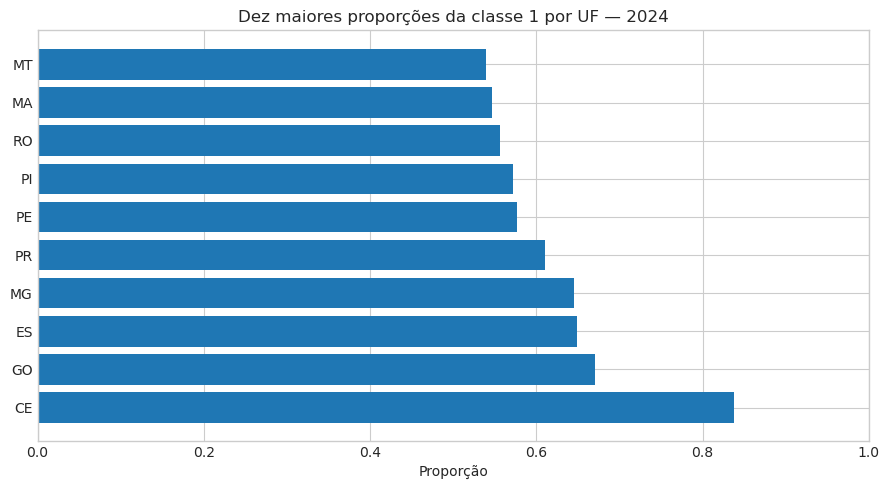

In [10]:
if COL_UF is not None:
    resumo_uf_ano=lf_analise.group_by([COL_ANO,COL_UF]).agg(pl.len().alias("quantidade_registros"),pl.col(COL_TARGET).mean().alias("proporcao_alfabetizado")).sort([COL_ANO,COL_UF]).collect(); display(resumo_uf_ano.head(30))
    anos_lista=resumo_uf_ano[COL_ANO].drop_nulls().unique().sort().to_list()
    if anos_lista:
        ano_recente=anos_lista[-1]; recorte=resumo_uf_ano.filter(pl.col(COL_ANO)==ano_recente).sort("proporcao_alfabetizado",descending=True).head(10)
        plt.figure(figsize=(9,5)); plt.barh(recorte[COL_UF].to_list(),recorte["proporcao_alfabetizado"].to_numpy()); plt.title(f"Dez maiores proporções da classe 1 por UF — {ano_recente}"); plt.xlabel("Proporção"); plt.xlim(0,1); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"263_9_comparacao_temporal_por_uf_01.png"); plt.show()
else: print("Coluna de UF não encontrada; comparação temporal por UF não realizada.")


## 10. Comparação temporal por rede de ensino

Quando a coluna de rede estiver disponível, a tabela permite comparar proporções e volumes entre anos e redes. Se `rede_descricao` estiver disponível, ela será utilizada para facilitar a leitura.


In [11]:
if COL_REDE is not None:
    resumo_rede_ano = (
        lf_analise.group_by([COL_ANO, COL_REDE])
        .agg([
            pl.len().alias("quantidade_registros"),
            pl.col(COL_TARGET).mean().alias("proporcao_alfabetizado"),
        ])
        .sort([COL_ANO, COL_REDE])
        .collect()
        
    )

    display(resumo_rede_ano)
else:
    print("Coluna de rede não encontrada; comparação temporal por rede não realizada.")


ano_referencia,rede_descricao,quantidade_registros,proporcao_alfabetizado
i64,str,u32,f64
2023,"""Estadual""",155140,0.51993
2023,"""Municipal""",1592299,0.500387
2024,"""Estadual""",280258,0.537933
2024,"""Municipal""",1840277,0.519673
2024,"""Privada""",25,0.64


## 11. Síntese dos achados

A síntese abaixo é preenchida a partir dos resultados calculados, sem atribuir causalidade. Os resultados devem ser interpretados à luz da cobertura e da comparabilidade dos anos.


In [12]:
anos_observados = cobertura_anos[COL_ANO].drop_nulls().to_list()
n_anos = len(anos_observados)

achados_temporais = []

achados_temporais.append({
    "tema": "Cobertura temporal",
    "observacao": f"Foram identificados {n_anos} anos distintos na coluna {COL_ANO}: {anos_observados}.",
    "limitacao": "A existência de vários anos não garante, por si só, que a cobertura e a composição dos registros sejam comparáveis."
})

if not resumo_anual.is_empty() and resumo_anual["proporcao_alfabetizado"].drop_nulls().len() > 0:
    validos_target = resumo_anual.drop_nulls("proporcao_alfabetizado")
    ano_min = validos_target.sort("proporcao_alfabetizado")[COL_ANO][0]
    ano_max = validos_target.sort("proporcao_alfabetizado", descending=True)[COL_ANO][0]
    min_pct = validos_target["proporcao_alfabetizado"].min() * 100
    max_pct = validos_target["proporcao_alfabetizado"].max() * 100
    achados_temporais.append({
        "tema": "Proporção do target",
        "observacao": f"A proporção anual da classe 1 variou de {min_pct:.2f}% ({ano_min}) a {max_pct:.2f}% ({ano_max}).",
        "limitacao": "A proporção corresponde à média do target binário na base, não necessariamente ao índice oficial calculado por outra metodologia."
    })

if "quantidade_registros" in resumo_anual.columns and len(resumo_anual) > 0:
    achados_temporais.append({
        "tema": "Volume de registros",
        "observacao": f"A quantidade de registros por ano variou de {int(resumo_anual['quantidade_registros'].min())} a {int(resumo_anual['quantidade_registros'].max())}.",
        "limitacao": "Variações de volume podem afetar a comparabilidade dos indicadores entre anos."
    })

achados_temporais.append({
    "tema": "Interpretação",
    "observacao": "As análises comparam indicadores agregados nos períodos observados, por ano e por grupos territoriais/administrativos disponíveis.",
    "limitacao": "Não foi realizado acompanhamento individual dos estudantes: a estabilidade de id_aluno entre anos não está validada. Diferenças temporais não comprovam causalidade e exigem avaliar cobertura, definições e disponibilidade das variáveis."
})

if n_anos < 3:
    achados_temporais.append({
        "tema": "Quantidade de períodos",
        "observacao": f"A base contém {n_anos} ano(s) distinto(s) identificado(s).",
        "limitacao": "Com menos de três períodos, a análise não deve ser descrita como uma tendência de longo prazo."
    })

display(pl.DataFrame(achados_temporais))


tema,observacao,limitacao
str,str,str
"""Cobertura temporal""","""Foram identificados 2 anos dis…","""A existência de vários anos nã…"
"""Proporção do target""","""A proporção anual da classe 1 …","""A proporção corresponde à médi…"
"""Volume de registros""","""A quantidade de registros por …","""Variações de volume podem afet…"
"""Interpretação""","""As análises comparam indicador…","""Não foi realizado acompanhamen…"
"""Quantidade de períodos""","""A base contém 2 ano(s) distint…","""Com menos de três períodos, a …"


## 12. Conclusão

Após executar as células, revise os resultados anuais, as diferenças observadas na proporção do target e nos indicadores educacionais, bem como as variações de volume e cobertura.

A interpretação deve se limitar aos anos e grupos efetivamente observados. Diferenças temporais são descritivas e não comprovam causalidade. A proporção da classe 1 de `alfabetizado` deve ser distinguida do índice oficial de alfabetização caso as metodologias de cálculo não sejam equivalentes.

As comparações deste notebook são agregadas por ano e, quando disponível, por UF, município ou rede. O campo `id_aluno` não é usado para vinculação longitudinal individual, pois sua estabilidade entre anos não está validada para esta análise. Antes de concluir, confira se os anos comparados possuem cobertura e definições compatíveis e registre limitações relevantes para as próximas etapas do projeto.

A cobertura territorial também variou entre os períodos: foram identificadas 23 UFs e 4.873 municípios em 2023, frente a 26 UFs e 5.519 municípios em 2024. Essa diferença deve ser considerada na interpretação das variações observadas, pois parte dos resultados pode refletir mudanças na cobertura e na composição dos registros.


<a id="fase-4"></a>

# Fase 4 — preparação, prevenção de leakage e baseline
